*This notebook was created by Sergey Tomin (sergey.tomin@desy.de) who was inspired by questions from E.R. Source and license info is on [GitHub](https://github.com/iagapov/ocelot/tree/dev/docs). June 2017.* 

<!--
twiss matching, optics design, beamline backtracking, FEL lattice, FODO, matching section, chicane, seeding optics
-->
# Tutorial N7: Lattice Design, Matching, and Twiss Backtracking

### Outline

- Design of a FODO lattice (undulator section) with specified maximum and minimum Twiss parameters  
- Backtracking through chicanes  
- Matching Twiss parameters in matching sections

---

### Introduction

In this tutorial, we design a basic FEL beamline for an external seeding configuration. The layout consists of:

- Matching section  
- Modulator – Chicane – Modulator – Chicane  
- FODO lattice (undulator section)

The FODO section consists of repeating cells:

- `undulator – QF – undulator – QD – undulator – QF – ...`

where `QF` and `QD` are focusing and defocusing quadrupoles, respectively.

We assume that:

1. The **maximum and minimum values** of the beta functions in the undulator section are known  
2. The **chicane geometry and parameters** are predefined  
3. The **Twiss parameters** at the entrance of the matching section are given

While this problem can be solved in multiple (and possibly simpler) ways, we take a structured approach to demonstrate the use of Ocelot’s matching and backtracking tools:

1. Match Twiss parameters within the FODO lattice to reach desired beta amplitudes using the [`match` function](https://www.ocelot-collab.com/docs/docu/OCELOT%20fundamentals/matching)  
2. Perform **Twiss backtracking** through the chicanes and modulators using the [`twiss` function](https://www.ocelot-collab.com/docs/docu/OCELOT%20fundamentals/twiss/#from_seriescls-series-pdseries)  
3. Use the [`MagneticLattice`](https://www.ocelot-collab.com/docs/docu/OCELOT%20fundamentals/magnet-lattice/) class to construct the full lattice

---

### Optics Design and Matching

Optics design is still something of an art — and only a few people in the world truly excel at it  
*(and the author of this notebook is certainly not one of them — at least not yet! :) ).*
 
This tutorial is not aimed at producing an optimal design, but rather to illustrate the **use of Ocelot’s matching functions** in a practical setting.


In [1]:
# the output of plotting commands is displayed inline within 
# frontends, directly below the code cell that produced it.
%matplotlib inline

from time import time 

# this python library provides generic shallow (copy) 
# and deep copy (deepcopy) operations 
from copy import deepcopy

# import from Ocelot main modules and functions

# import from Ocelot graphical modules


## Step 1. FODO lattice matching 
### Design the simplest FODO lattice

In [2]:
from ocelot.cpbd.elements import Drift, Marker, Quadrupole, Undulator

# example of the FODO
U = Undulator(nperiods=50, lperiod=0.04, Kx=1)
D = Drift(l=0.5)
QF = Quadrupole(l=0.25, k1=1)
QD = Quadrupole(l=0.25, k1=-1)

M1 = Marker()
cell = (M1, QF, D, U, D, QD, QD, D, U, D, QF)

# suppose we have 5 cells or 10 undulators
fodo = cell*5

### Periodic solution for FODO lattice
**Note**

* In the most cases to find twiss periodical solution we do not need to put the initial conditions and we can use following command to calculate twiss parameters:
**tws = periodic_twiss(lat)** 

**BUT**

* To take into account undulator vertical focusing effect we have to define the energy of the electron beam. and in that case we have to define initial condition like that: 


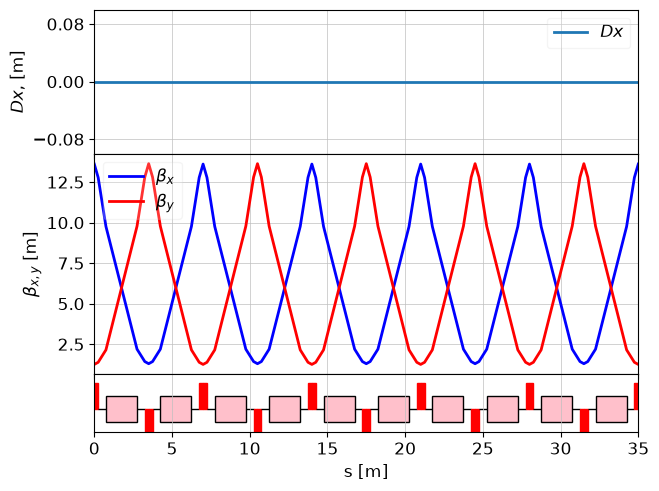

In [3]:
import matplotlib.pyplot as plt
from ocelot.cpbd.beam.core import Twiss
from ocelot.cpbd.magnetic_lattice import MagneticLattice
from ocelot.cpbd.optics import periodic_twiss
from ocelot.gui.accelerator import plot_opt_func

# create MagneticLattice object
lat_fodo = MagneticLattice(fodo)

tws0 = Twiss()
# The seed supplies the energy needed to calculate focusing.

# print(tws0)

# And we need to define the beam energy
tws0.E = 1 # GeV

tws = periodic_twiss(lat_fodo, tws0=tws0)

plot_opt_func(lat_fodo, tws, legend=False)
plt.show()

### Matching

In Ocelot there is function match() to perform some standard matching procedures. 
```python
def match(lat, constr, vars, tw):
    ...
    return res
```
where 
* ```lat```: MagneticLattice
* ```constr```: dictionary, constrains. Example:

    - 'periodic':True - means the "match" function tries to find periodic solution at the ends of lattice:
        
        ```constr = {elem1:{'beta_x':15, 'beta_y':2}, 'periodic':True}``` 
         
    - "hard" constrains on the end of elements (elem1, elem2):
         
        ```constr = {elem1:{'alpha_x':5, 'beta_y':5}, elem2:{'Dx':0 'Dyp':0, 'alpha_x':5, 'beta_y':5}}``` 
        
    - or mixture of "soft" and hard constrains:
        
        ```constr = {elem1:{'alpha_x':[">", 5], 'beta_y':5}, elem2:{'Dx':0 'Dyp':0, 'alpha_x':5, 'beta_y':[">", 5]}}```
        
    - in case one needs global control on beta function, the constrains can be written following way.
         
        ```constr = {elem1:{'alpha_x':5, 'beta_y':5}, 'global': {'beta_x': ['>', 10]}}``` 
        
        
* ```vars```: list of elements which will be varied during optimization, e.g. vars = [QF, QD]
    
    can be 
        - Quadrupole (vary strength 'k1'), 
        - SBend, RBend, Bend (by default vary 'k1' but can be "angle"), 
        - Solenoid (vary strength "k"), 
        - Drift (vary length "l")
* ```tw```: Twiss(), initial Twiss

***Optional arguments:***

* ```verbose```: True, allow print output of minimization procedure
* ```max_iter```: 1000, number of iterations
* ```method```: string, available 'simplex', 'cg', 'bfgs'
* ```weights```: function returns weights, for example
    - ```python
    def weights_default(val):
        if val == 'periodic': return 10000001.0
        if val == 'total_len': return 10000001.0
        if val in ['Dx', 'Dy', 'Dxp', 'Dyp']: return 10000002.0
        if val in ['alpha_x', 'alpha_y']: return 100007.0
        if val in ['mux', 'muy']: return 10000006.0
        if val in ['beta_x', 'beta_y']: return 100007.0
        return 0.0001
       ```
* ```vary_bend_angle```: False, allow to vary "angle" of the dipoles instead of the focusing strength "k1"
* ```min_i5```: False, minimization of the radiation integral I5. Can be useful for storage rings optimizations.
* ```return``` result

initial value: x =  [1, -1]
Optimization terminated successfully.
         Current function value: 0.000017
         Iterations: 42
         Function evaluations: 82
QF.k1 =  1.071039959675296
QD.k1 =  -0.8579474979724729


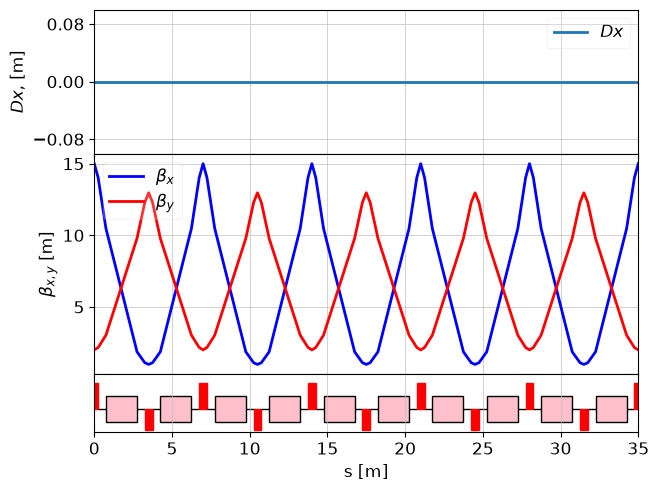

In [4]:
import matplotlib.pyplot as plt
from ocelot.cpbd.beam.core import Twiss
from ocelot.cpbd.match import match
from ocelot.cpbd.optics import periodic_twiss
from ocelot.gui.accelerator import plot_opt_func

# constrains
constr = {M1:{'beta_x':15, 'beta_y':2}, 'periodic':True}

# variables
vars = [QF, QD]

# initial condition for twiss
tw0=tws[-1]

match(lat_fodo, constr, vars, tw0, verbose=False)

# results 
print("QF.k1 = ", QF.k1)
print("QD.k1 = ", QD.k1)


tws0=Twiss()
tws0.E = 1 # GeV

tws = periodic_twiss(lat_fodo, tws0=tws0)

# let's variable *tws_fodo* will be the twiss 
# parameters on the FODO entrance 
tws_fodo = tws[-1]

plot_opt_func(lat_fodo, tws, legend=False)
plt.show()

## Step 2. Chicanes. 

In [5]:
import numpy as np
from ocelot.cpbd.elements import Bend, Drift, Marker, Undulator

# undulator + chicane + undulator + chicane
modulator = Undulator(nperiods=10, lperiod=0.1, Kx = 2)

# Chicane from CSR example with small modifications 

b1 = Bend(l = 0.5, angle=-0.0336, e1=0.0, e2=-0.0336, gap=0, tilt=0, eid='BB.393.B2')
b2 = Bend(l = 0.5, angle=0.0336, e1=0.0336, e2=0.0, gap=0, tilt=0,  eid='BB.402.B2')
b3 = Bend(l = 0.5, angle=0.0336, e1=0.0, e2=0.0336, gap=0, tilt=0, eid='BB.404.B2')
b4 = Bend(l = 0.5, angle=-0.0336, e1=-0.0336, e2=0.0, gap=0, tilt=0, eid='BB.413.B2')

d = Drift(l=1.5/np.cos(b2.angle))

start_csr = Marker()
stop_csr = Marker()

# define chicane frome the bends and drifts
chicane = [start_csr, Drift(l=1), b1, d, b2, 
           Drift(l=1.5), b3, d, b4, Drift(l= 1.), stop_csr]


# For sake of buity add randomly couple of the quadrupoles

D1 = Drift(l=0.5)
echo = (D1, QF, D1, modulator, D1, QD, chicane,  QF, D1, modulator,D1, QD, chicane)


#### Chicane parameters
For example, one wants to know R56 of the whole chicane. It can be easily calculated

In [6]:
from ocelot.cpbd.magnetic_lattice import MagneticLattice
from ocelot.cpbd.optics import lattice_transfer_map

lat_chic = MagneticLattice(chicane)
# in that case energy is not important we do not have 
# energy dependant elements here
R = lattice_transfer_map(lat_chic, energy=0)
print("R56 = ", R[4,5]*1000, "mm")

R56 =  -4.1443249349333655 mm


### Backtracking though chicanes.
We know twiss parameters on the entrance of the FODO
but for backtracking we need to 
* invert alphas 
* and invert the lattice (change the order of the element)

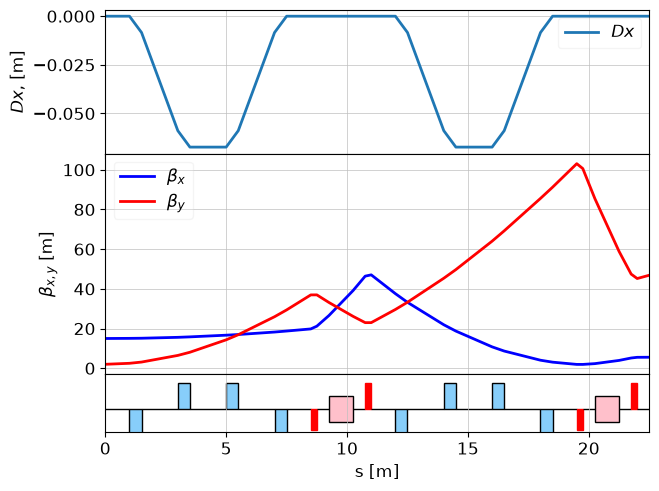

In [7]:
import matplotlib.pyplot as plt
from ocelot.cpbd.beam.core import Twiss
from ocelot.cpbd.magnetic_lattice import MagneticLattice
from ocelot.cpbd.optics import twiss
from ocelot.gui.accelerator import plot_opt_func

# inverting alphas

tws2 = Twiss()
tws2.alpha_x = -tws_fodo.alpha_x
tws2.alpha_y = -tws_fodo.alpha_y
tws2.beta_x = tws_fodo.beta_x
tws2.beta_y = tws_fodo.beta_y

# invert the lattice
echo_inv = echo[::-1]
lat_echo_inv = MagneticLattice(echo_inv)

# calculate twiss 
tws_echo = twiss(lat_echo_inv, tws0=tws2)
tws_echo_inv_end = tws_echo[-1]

# show the twiss parameters of INVERTED echo
plot_opt_func(lat_echo_inv, tws_echo, legend=False)
plt.show()

So twiss parameters on the entrance of the echo lattice are: 

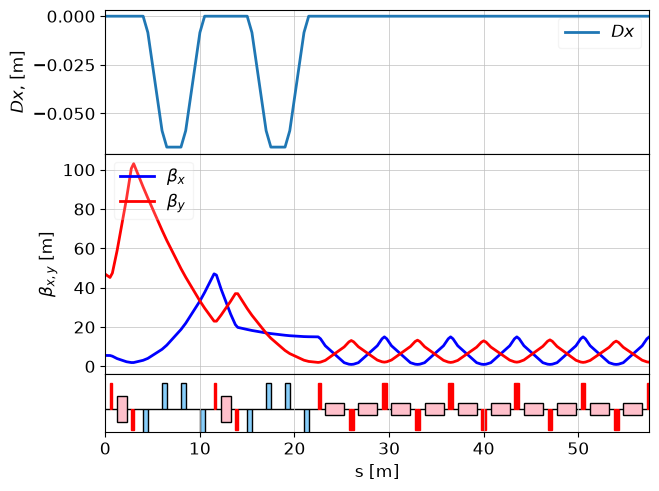

In [8]:
import matplotlib.pyplot as plt
from ocelot.cpbd.beam.core import Twiss
from ocelot.cpbd.magnetic_lattice import MagneticLattice
from ocelot.cpbd.optics import twiss
from ocelot.gui.accelerator import plot_opt_func

# inverting alphas again is needed
tws_e = Twiss()
tws_e.beta_x = tws_echo_inv_end.beta_x
tws_e.beta_y = tws_echo_inv_end.beta_y
tws_e.alpha_x = -tws_echo_inv_end.alpha_x
tws_e.alpha_y = -tws_echo_inv_end.alpha_y

lat_echo_fodo = MagneticLattice((echo, fodo) )

tws_all = twiss(lat_echo_fodo, tws_e)

plot_opt_func(lat_echo_fodo, tws_all, legend=False)
plt.show()

## Step 3.  Matching section

In [9]:
from ocelot.cpbd.elements import Drift, Marker, Quadrupole
from ocelot.cpbd.magnetic_lattice import MagneticLattice

Q1 = Quadrupole(l=0.3, k1=1)
Q2 = Quadrupole(l=0.3, k1=1)
Q3 = Quadrupole(l=0.3, k1=1)
Q4 = Quadrupole(l=0.3, k1=1)


m1 = Marker()
m2 = Marker()
dm = Drift(l=1.5)
match_sec = (m1, dm, Q1, dm, Q2, dm, Q3, dm, Q4, dm, m2)

lat_m = MagneticLattice(match_sec[::-1])

#### Matching
As it was mentioned above, matching will not give you desired values if your geometry of initial conditions are poor. Because our goal is not a good design but showing the concept of OCELOT usage, we choose very relax condition. 
Twiss parameters on the entrance of the matching section:

- beta_x = 5 
- beta_y = 5
- alpha_x = not defined
- alpha_y = not defined

the twiss parameters on the exit of matching section are defined by echo section

initial value: x =  [1, 1, 1, 1]
Optimization terminated successfully.
         Current function value: 214917575.120251
         Iterations: 106
         Function evaluations: 197
Q1.k1 =  2.355853351631101
Q2.k1 =  -1.3155292135369026
Q3.k1 =  -0.9164603176527466
Q4.k1 =  1.332649679467849


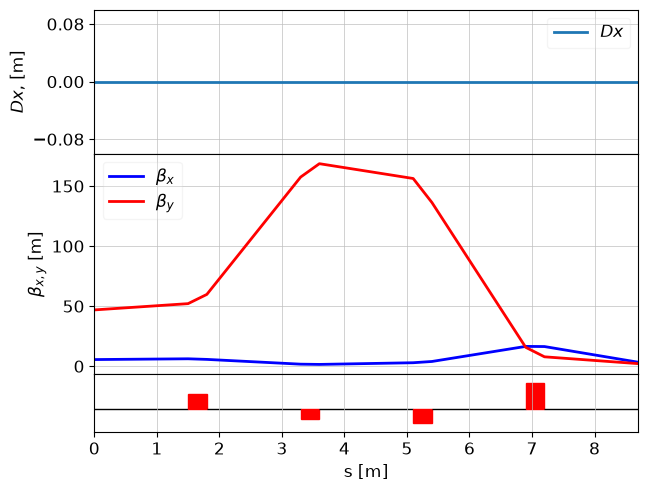

In [10]:
import matplotlib.pyplot as plt
from ocelot.cpbd.beam.core import Twiss
from ocelot.cpbd.match import match
from ocelot.cpbd.optics import twiss
from ocelot.gui.accelerator import plot_opt_func

# constrains
constr = {m1:{'beta_x':5, 'beta_y':5}, 
          m2:{'beta_x':tws_e.beta_x, 'beta_y':tws_e.beta_y, 
              'alpha_x': -tws_e.alpha_x, "alpha_y":-tws_e.alpha_y}}

# variables
vars = [Q1, Q2, Q3,Q4]

# initial condition for twiss

match(lat_m, constr, vars, tw0, verbose=False)

for i, q in enumerate(vars):
    print("Q"+str(i+1)+".k1 = ", q.k1)

tws0 = Twiss()
tws0.beta_x = tws_e.beta_x
tws0.beta_y = tws_e.beta_y
tws0.alpha_x = -tws_e.alpha_x
tws0.alpha_y = -tws_e.alpha_y

tws = twiss(lat_m, tws0)
plot_opt_func(lat_m, tws, legend=False)
plt.show()

tws0 = tws[-1]
tws0.alpha_x = -tws[-1].alpha_x
tws0.alpha_y = -tws[-1].alpha_y

## FINAL Lattice

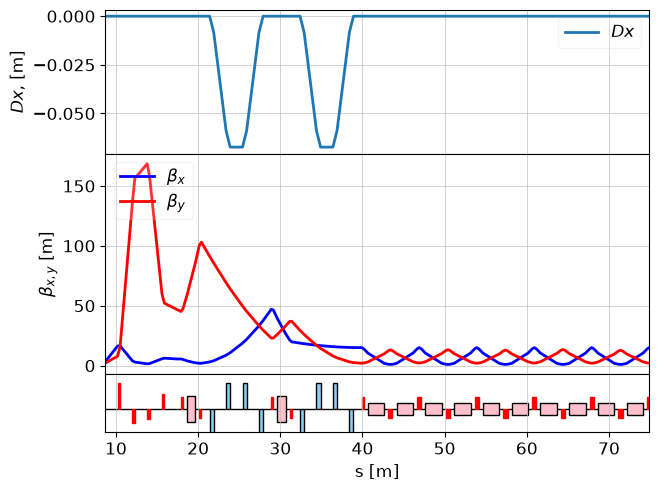

In [11]:
import matplotlib.pyplot as plt
from ocelot.cpbd.magnetic_lattice import MagneticLattice
from ocelot.cpbd.optics import twiss
from ocelot.gui.accelerator import plot_opt_func

cell = (match_sec, echo, fodo)
# fodo quadrupoles

lat = MagneticLattice(cell)

tws = twiss(lat, tws0)
plot_opt_func(lat, tws, legend=False)
plt.show()